# Tracer dispersion 3: Lagrangian particles against the Eulerian solution

**37EFM Environmental Fluid Mechanics, TU/e**

Instead of a concentration field, follow $N$ particles. Each one is advected by $u(z)$ and takes random steps whose size is set by the diffusivity, as in the random walk of Chapter 6. The equations are stochastic differential equations,

$$dx = u(z)\,dt + \sqrt{2D_x}\,dW_x, \qquad dz = \frac{dD}{dz}\,dt + \sqrt{2D(z)}\,dW_z ,$$

with $dW$ Gaussian increments of variance $dt$. The drift $dD/dz$ is not a correction for the sake of accuracy: without it, the particles pile up where $D$ is small, and a uniformly distributed tracer does not stay uniform. With it, the concentration of the particle cloud obeys the same equation as the Eulerian solver, with $D(z)$ inside the derivative.

Time stepping is a second-order Runge-Kutta scheme ("RK2", scheme `rk2`): a predictor step, then the velocity $u$ and the drift $dD/dz$ are averaged between the start of the step and the predicted end point, with the *same* random increments in both. The random part carries Milstein's correction $\tfrac12 (dD/dz)(dW_z^2 - dt)$ for the $z$-dependence of the noise amplitude, which matters near the walls where $D \to 0$. Read `efmtracer/lagrangian.py`; the module also has the first-order Euler-Maruyama scheme (`euler`) and a deliberately wrong one (`naive`).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from efmtracer import eulerian, lagrangian, profiles, theory
plt.rcParams['figure.dpi'] = 80

## The well-mixed test

Release particles uniformly over the depth of the Couette flow and let them walk for one transverse diffusion time with the three schemes of the module. The distribution must stay uniform.

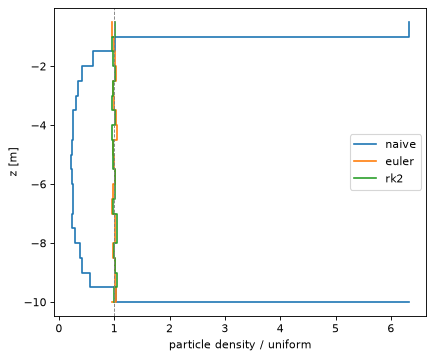

In [2]:
prof = profiles.couette()
H = prof.H
T_mix = theory.mixing_time(H, prof.D_mean)
rng = np.random.default_rng(1)
N = 40000
fig, ax = plt.subplots(figsize=(6, 5))
for scheme in ['naive', 'euler', 'rk2']:
    z0 = rng.uniform(-H, 0, N); x0 = np.zeros(N)
    _, pos, _ = lagrangian.run(x0, z0, dt=2.0, t_end=T_mix, prof=prof, rng=rng, scheme=scheme)
    counts, edges = np.histogram(pos[-1][1], bins=20, range=(-H, 0))
    ax.step(counts / counts.mean(), edges[:-1], where='post', label=scheme)
ax.axvline(1, color='gray', ls='--', lw=0.8)
ax.set_xlabel('particle density / uniform'); ax.set_ylabel('z [m]'); ax.legend();

## The blob, both ways

Release the blob of notebook 2 as particles, with the same Gaussian distribution, and run both the particles and the Eulerian solver for four hours in the Couette flow. The particle positions are binned on the Eulerian grid to compare concentrations.

In [3]:
t_end = 4 * 3600
grid = eulerian.Grid(L=4000, nx=800, H=H, nz=100)
c0 = eulerian.gaussian_blob(grid, x0=2000, z0=-H / 2, sigma_x=5.0, sigma_z=0.5)
solver = eulerian.Solver(grid, prof.u, prof.D)
times, snaps, hist_e = solver.run(c0, dt=5.0, t_end=t_end, save_every=3600)

N = 20000
x0, z0 = lagrangian.release_blob(N, 2000, -H / 2, 5.0, 0.5, H, rng)
times_l, pos, hist_l = lagrangian.run(x0, z0, dt=2.0, t_end=t_end, prof=prof, rng=rng, scheme='rk2',
                                      save_every=3600, u_frame=solver.u_frame)
print(f'Eulerian: {len(hist_e["t"]) - 1} steps on {grid.nz} x {grid.nx} cells;  Lagrangian: {len(hist_l["t"]) - 1} steps for {N} particles')

Eulerian: 2880 steps on 100 x 800 cells;  Lagrangian: 7200 steps for 20000 particles


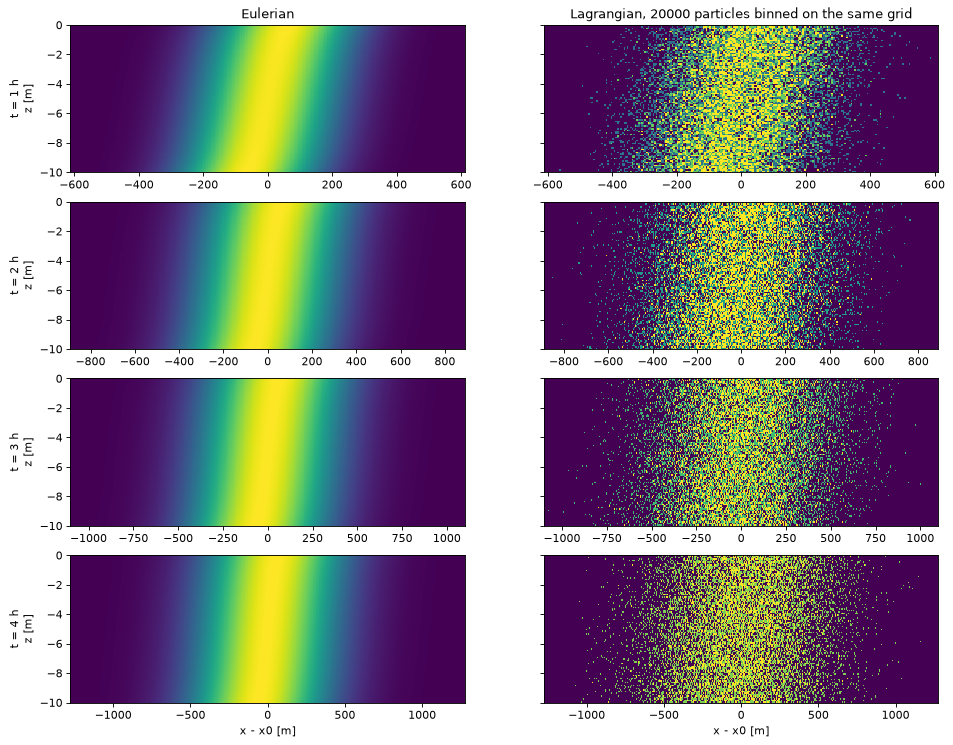

In [4]:
fig, axs = plt.subplots(4, 2, figsize=(14, 11), sharey=True)
for row, k in enumerate([1, 2, 3, 4]):
    c = snaps[k]
    xl, zl = pos[k]
    cl = lagrangian.concentration(xl, zl, grid, L_wrap=grid.L)
    cx = c.sum(axis=0); cm = (cx * grid.x).sum() / cx.sum(); sx = np.sqrt(((grid.x - cm) ** 2 * cx).sum() / cx.sum())
    vmax = c.max()
    axs[row, 0].pcolormesh(grid.x - 2000, grid.z, c, vmin=0, vmax=vmax, cmap='viridis', shading='nearest')
    axs[row, 1].pcolormesh(grid.x - 2000, grid.z, cl, vmin=0, vmax=vmax, cmap='viridis', shading='nearest')
    for ax in axs[row]:
        ax.set_xlim(cm - 2000 - 4 * sx, cm - 2000 + 4 * sx)
    axs[row, 0].set_ylabel(f't = {times[k] / 3600:.0f} h\nz [m]')
axs[0, 0].set_title('Eulerian'); axs[0, 1].set_title(f'Lagrangian, {N} particles binned on the same grid')
for ax in axs[-1]: ax.set_xlabel('x - x0 [m]')

The particle field is noisy: with $N$ particles in a bin the relative fluctuation is $1/\sqrt{N}$. The depth-averaged profiles and the moments compare more fairly.

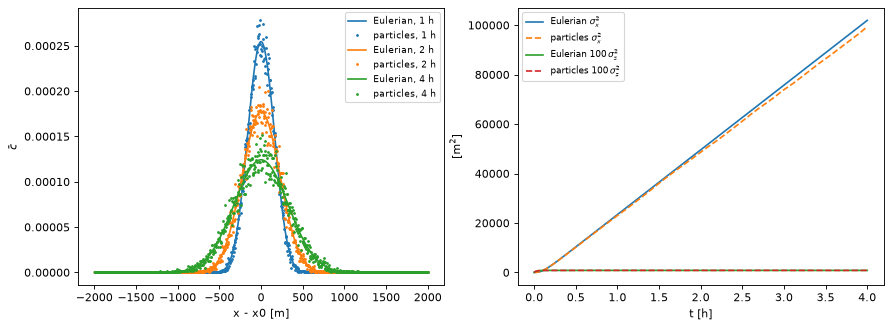

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for k, color in zip([1, 2, 4], ['C0', 'C1', 'C2']):
    ax1.plot(grid.x - 2000, eulerian.depth_average(snaps[k], grid), color=color, label=f'Eulerian, {times[k] / 3600:.0f} h')
    cl = lagrangian.concentration(*pos[k], grid, L_wrap=grid.L)
    ax1.plot(grid.x - 2000, eulerian.depth_average(cl, grid), '.', color=color, ms=3, label=f'particles, {times[k] / 3600:.0f} h')
ax1.set_xlabel('x - x0 [m]'); ax1.set_ylabel(r'$\bar c$'); ax1.legend(fontsize=8)

ax2.plot(hist_e['t'] / 3600, hist_e['var_x'], label=r'Eulerian $\sigma_x^2$')
ax2.plot(hist_l['t'] / 3600, hist_l['var_x'], '--', label=r'particles $\sigma_x^2$')
ax2.plot(hist_e['t'] / 3600, hist_e['var_z'] * 100, label=r'Eulerian $100\,\sigma_z^2$')
ax2.plot(hist_l['t'] / 3600, hist_l['var_z'] * 100, '--', label=r'particles $100\,\sigma_z^2$')
ax2.set_xlabel('t [h]'); ax2.set_ylabel('[m$^2$]'); ax2.legend(fontsize=8);

## Questions

1. Run the blob with the `naive` scheme. Where do the particles end up, and what does that do to $\sigma_x^2$? Explain with the well-mixed test.
2. Compare `euler` and `rk2` at time steps of 2, 10 and 30 s, against the Eulerian solution. Which one degrades first, and in which quantity? Why does a coarse step make the patch spread *less*?
3. How many particles are needed for the depth-averaged profile to be as smooth as the Eulerian one to within 5 %? Estimate from $1/\sqrt{N}$ per bin, then check.
4. Both methods conserve mass; only one conserves it exactly in the form of a count. Which quantity does the Eulerian solver conserve exactly, and why?
5. Which of the two methods would you use for a river 10 km long, and which for a point source next to a wall? Think about cost, noise and the near-field.